In [1]:
#%pip install torch matplotlib scipy
import torch
import matplotlib.pyplot as plt
from scipy.io import loadmat

In [2]:
def init_params(nx, nh, ny):
    params = {}
    params["W1"] = torch.randn(nh, nx) * 0.3
    params["b1"] = torch.randn(1, nh) * 0.3
    params["W2"] = torch.randn(ny, nh) * 0.3
    params["b2"] = torch.randn(1, ny) * 0.3
    for k in params:
        params[k].requires_grad = True
    return params

In [3]:
def forward (params, X):
    outputs = {}
    outputs["X"] = X
    outputs["h_tilde"] = torch.mm(X, params["W1"].T) + params["b1"]
    outputs["h"] = torch.tanh(outputs["h_tilde"])
    outputs["y_tilde"] = torch.mm(outputs["h"], params["W2"].T) + params["b2"]
    exp_y = torch.exp(outputs["y_tilde"])
    outputs["y_hat"] = exp_y / torch.sum(exp_y, dim=1, keepdim=True)
    return outputs, outputs["y_hat"]

In [4]:
def loss_accuracy(y_hat, y):
    # adding 1e-12 to avoid log(0)
    L = -torch.mean(torch.sum(y * torch.log(y_hat + 1e-12), dim=1))

    _, indsY = torch.max(y, 1)
    _, indsYhat = torch.max(y_hat, 1)
    acc = torch.mean((indsY == indsYhat).float())

    return L, acc

In [5]:
def sgd(params, eta):
    # no_grad: the update itself must not be recorded in the computation graph
    with torch.no_grad():
        for k in params:
            params[k] -= eta * params[k].grad
            params[k].grad.zero_()  # avoid gradients accumulation across backward() calls
    return params

epoch   0 | train loss 0.3120 acc 0.906 | test loss 0.3049 acc 0.908
epoch   1 | train loss 0.2405 acc 0.930 | test loss 0.2437 acc 0.927
epoch   2 | train loss 0.2054 acc 0.939 | test loss 0.2171 acc 0.935
epoch   3 | train loss 0.1810 acc 0.947 | test loss 0.1974 acc 0.942
epoch   4 | train loss 0.1603 acc 0.954 | test loss 0.1830 acc 0.945
epoch   5 | train loss 0.1461 acc 0.958 | test loss 0.1720 acc 0.948
epoch   6 | train loss 0.1374 acc 0.960 | test loss 0.1673 acc 0.952
epoch   7 | train loss 0.1236 acc 0.964 | test loss 0.1560 acc 0.954
epoch   8 | train loss 0.1149 acc 0.967 | test loss 0.1491 acc 0.955
epoch   9 | train loss 0.1078 acc 0.969 | test loss 0.1441 acc 0.957
epoch  10 | train loss 0.1007 acc 0.971 | test loss 0.1396 acc 0.957
epoch  11 | train loss 0.0941 acc 0.973 | test loss 0.1363 acc 0.958
epoch  12 | train loss 0.0885 acc 0.975 | test loss 0.1342 acc 0.960
epoch  13 | train loss 0.0853 acc 0.976 | test loss 0.1321 acc 0.961
epoch  14 | train loss 0.0795 acc 

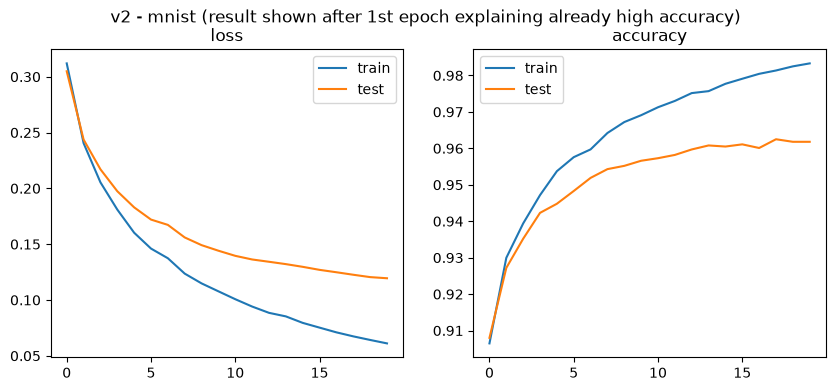

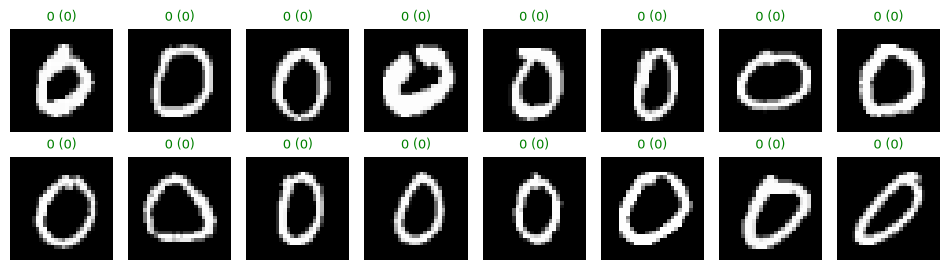

In [7]:
import utils
utils.set_seed(42)

data = utils.load_data("mnist")
nh, Nbatch, eta, Nepoch = 100, 64, 0.1, 20

params = init_params(data[0].shape[1], nh, data[1].shape[1])

def step(Xb, yb):
    _, y_hat = forward(params, Xb)
    L, _ = loss_accuracy(y_hat, yb)
    L.backward()  # computes params[k].grad for every k
    sgd(params, eta)

def predict(X):
    return forward(params, X)[1]

curves = utils.train(step, predict, data, Nbatch, Nepoch)
utils.plot_curves(curves, "v2 - mnist (result shown after 1st epoch explaining already high accuracy)")
utils.show_mnist(data[2], data[3], predict)